# Detección de fraude con datos reales: IEEE-CIS

El notebook anterior mostró que en los datos sintéticos el fraude se detecta con una sola regla
(`monto > $1,500`). Aquí se repite el ejercicio con transacciones reales para ver cómo se ve un
problema de fraude de verdad.

**Datos:** *IEEE-CIS Fraud Detection* (Kaggle, 2019). Son transacciones de comercio electrónico
con tarjeta, aportadas por la empresa de pagos Vesta. El archivo de entrenamiento tiene
590,540 transacciones de unos seis meses. Muchas columnas vienen anonimizadas (`C1`, `D1`, `V1`…)
para proteger a los clientes, así que no siempre se sabe qué significan.

**Cómo conseguir los datos:** entra a la competencia en Kaggle y acepta sus reglas (botón *Join
Competition*). Después, el notebook los descarga solo con `kagglehub`, usando tu token de Kaggle
(`~/.kaggle/kaggle.json` o las variables `KAGGLE_USERNAME` y `KAGGLE_KEY`). Los datos son de la
competencia: no los subas a tu repositorio, solo enlázalos.

**Mismo método que en la auditoría:** partición temporal, líneas base simples, el mismo presupuesto
de revisión (3.35% de las transacciones) y un umbral elegido por costo.

In [1]:
import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb                      # pip install lightgbm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
ROJO, VERDE, GRIS, AZUL = "#c4566b", "#2f7f6c", "#9aa3b2", "#3d5fa8"

# Si ya tienes los CSV, pon su carpeta en RUTA_IEEE; si no, se descargan de Kaggle.
RUTA = os.environ.get("RUTA_IEEE")
if RUTA is None:
    import kagglehub                          # pip install kagglehub
    RUTA = kagglehub.competition_download("ieee-fraud-detection")
print("Datos en:", RUTA)

## 1. Carga

El CSV pesa unos 680 MB. Para que quepa en una laptop se leen las columnas numéricas como
`float32` (la mitad de memoria que `float64`).

In [2]:
encabezado = pd.read_csv(os.path.join(RUTA, "train_transaction.csv"), nrows=0).columns
tipos = {c: "float32" for c in encabezado
         if c.startswith(("V", "C", "D", "card", "addr", "dist")) and c not in ("card4", "card6")}
trans = pd.read_csv(os.path.join(RUTA, "train_transaction.csv"), dtype=tipos)
ident = pd.read_csv(os.path.join(RUTA, "train_identity.csv"))
df = trans.merge(ident, on="TransactionID", how="left")
del trans, ident; gc.collect()

for c in df.select_dtypes("number").columns:
    if df[c].dtype == "float64":
        df[c] = df[c].astype("float32")
df = df.copy()   # compacta el DataFrame en memoria

# TransactionDT son segundos desde una fecha de referencia que no se publicó
df["dia"] = df["TransactionDT"] / 86_400
df["hora"] = ((df["TransactionDT"] // 3600) % 24).astype("int8")

print(f"{len(df):,} transacciones, {df.shape[1]} columnas, {df.memory_usage().sum()/1e9:.1f} GB en memoria")
print(f"Fraudes: {df['isFraud'].sum():,} ({df['isFraud'].mean():.2%})")
print(f"Periodo: día {df['dia'].min():.0f} al {df['dia'].max():.0f}")

590,540 transacciones, 436 columnas, 1.1 GB en memoria
Fraudes: 20,663 (3.50%)
Periodo: día 1 al 183


## 2. ¿Qué tan difícil es el problema?

La misma pregunta que en los datos sintéticos. Allá, el monto solo daba un ROC-AUC de 0.997.

ROC-AUC usando solo el monto: 0.498   (0.5 = azar)


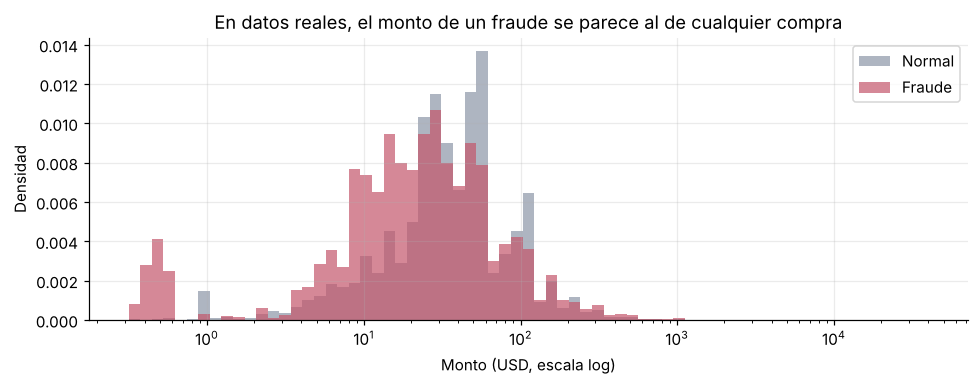

In [3]:
auc_monto = roc_auc_score(df["isFraud"], df["TransactionAmt"])
print(f"ROC-AUC usando solo el monto: {auc_monto:.3f}   (0.5 = azar)")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(-0.5, 4.6, 70)
ax.hist(df.loc[df["isFraud"] == 0, "TransactionAmt"], bins=bins, color=GRIS, alpha=.8, density=True, label="Normal")
ax.hist(df.loc[df["isFraud"] == 1, "TransactionAmt"], bins=bins, color=ROJO, alpha=.7, density=True, label="Fraude")
ax.set_xscale("log"); ax.set_xlabel("Monto (USD, escala log)"); ax.set_ylabel("Densidad")
ax.set_title("En datos reales, el monto de un fraude se parece al de cualquier compra")
ax.legend(); plt.tight_layout(); plt.show()

**El monto solo no sirve para nada** (ROC-AUC ≈ 0.5). Los fraudes reales tienen montos normales.
Ninguna regla de una línea va a resolver esto.

### ¿Dónde hay señal?

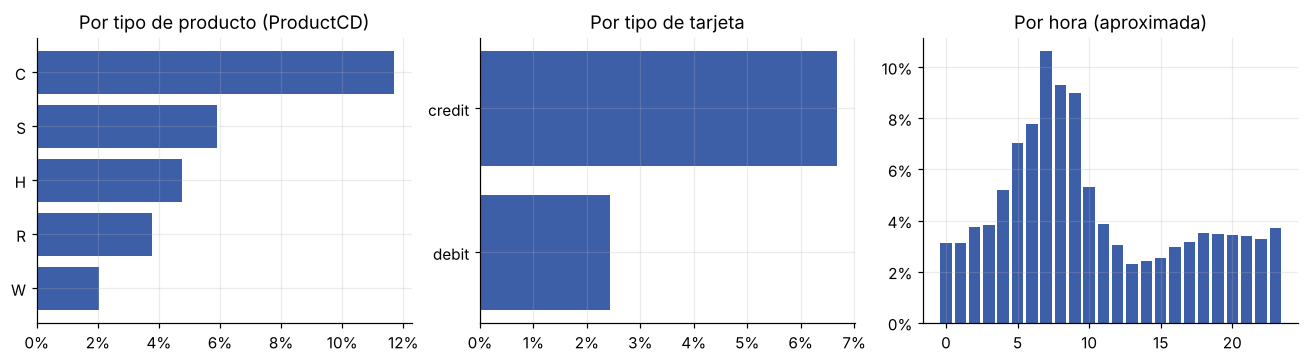

,mean,count
ProductCD,,
W,0.020,439670
R,0.038,37699
H,0.048,33024
S,0.059,11628
C,0.117,68519


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
tasa_prod = df.groupby("ProductCD")["isFraud"].agg(["mean", "count"]).sort_values("mean")
axes[0].barh(tasa_prod.index, tasa_prod["mean"], color=AZUL)
axes[0].set_title("Por tipo de producto (ProductCD)")
tasa_tarj = df.groupby("card6")["isFraud"].agg(["mean", "count"]).query("count > 1000").sort_values("mean")
axes[1].barh(tasa_tarj.index, tasa_tarj["mean"], color=AZUL)
axes[1].set_title("Por tipo de tarjeta")
tasa_hora = df.groupby("hora")["isFraud"].mean()
axes[2].bar(tasa_hora.index, tasa_hora.values, color=AZUL)
axes[2].set_title("Por hora (aproximada)")
for a in axes:
    (a.xaxis if a is not axes[2] else a.yaxis).set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()
tasa_prod

Hay señal repartida: el producto `C` tiene 3 veces la tasa promedio, las tarjetas de crédito más que
las de débito, y la madrugada (hora aproximada, porque la fecha de referencia no se publicó) un poco más.
Ninguna señal sola alcanza. Por eso aquí un modelo sí tiene trabajo que hacer.

### El fraude cambia con el tiempo

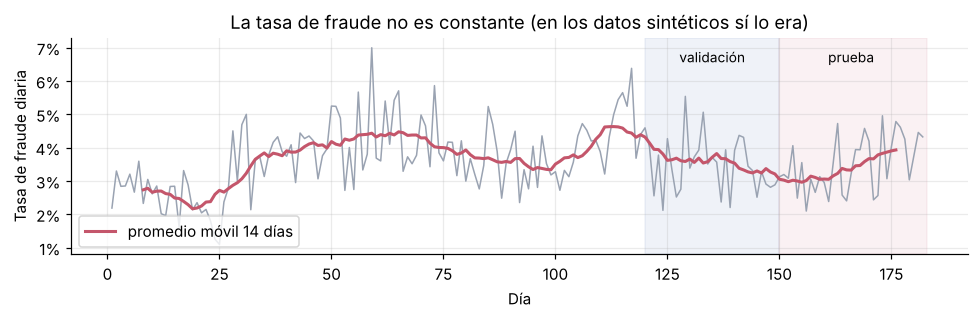

In [5]:
diaria = df.groupby(df["dia"].astype(int))["isFraud"].mean()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(diaria.index, diaria.values, color=GRIS, lw=1)
ax.plot(diaria.rolling(14, center=True).mean(), color=ROJO, lw=2, label="promedio móvil 14 días")
ax.axvspan(120, 150, color=AZUL, alpha=.08); ax.axvspan(150, 183, color=ROJO, alpha=.08)
ax.text(135, ax.get_ylim()[1]*.9, "validación", ha="center", fontsize=9)
ax.text(166, ax.get_ylim()[1]*.9, "prueba", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Día"); ax.set_ylabel("Tasa de fraude diaria"); ax.legend(loc="lower left")
ax.set_title("La tasa de fraude no es constante (en los datos sintéticos sí lo era)")
plt.tight_layout(); plt.show()

## 3. Partición temporal

- **Entrenamiento:** días 1 a 120 (unos 4 meses)
- **Validación:** días 121 a 150, para decidir cuándo dejar de entrenar
- **Prueba:** días 151 a 183, el último mes, que el modelo nunca ve

Así se simula lo que pasa en producción: entrenar con el pasado y usar el modelo en el futuro.

In [6]:
CATEGORICAS = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in CATEGORICAS:
    df[c] = df[c].astype("category")
ATRIBUTOS = [c for c in df.columns if c not in ("TransactionID", "isFraud", "TransactionDT", "dia")]

i_tr = df.index[df["dia"] <= 120]
i_va = df.index[(df["dia"] > 120) & (df["dia"] <= 150)]
i_te = df.index[df["dia"] > 150]
y_te = df.loc[i_te, "isFraud"].values
print(f"Atributos: {len(ATRIBUTOS)} ({len(CATEGORICAS)} categóricos)")
for n, i in [("entrenamiento", i_tr), ("validación", i_va), ("prueba", i_te)]:
    print(f"  {n:14s} {len(i):>8,} filas   fraude {df.loc[i, 'isFraud'].mean():.2%}")

Atributos: 432 (31 categóricos)
  entrenamiento   410,601 filas   fraude 3.51%
  validación       85,304 filas   fraude 3.47%
  prueba           94,635 filas   fraude 3.47%


In [7]:
PRESUPUESTO = 0.0335   # mismo presupuesto de revisión que en el proyecto original

def metricas(y, prob, nombre):
    y = np.asarray(y)
    k = int(round(PRESUPUESTO * len(y)))
    top = np.argsort(-prob)[:k]
    return {"modelo": nombre,
            "PR-AUC": average_precision_score(y, prob),
            "ROC-AUC": roc_auc_score(y, prob),
            f"recall revisando {PRESUPUESTO:.2%}": y[top].sum() / y.sum(),
            f"precisión revisando {PRESUPUESTO:.2%}": y[top].mean()}

resultados = []

## 4. Líneas base

Antes del modelo complejo, dos referencias:
1. **Regla:** revisar primero el producto `C`, el de mayor tasa de fraude.
2. **Regresión logística** con un puñado de atributos claros: monto, producto, tipo de tarjeta,
   hora y los contadores `C1`–`C14`.

In [8]:
regla = (df.loc[i_te, "ProductCD"] == "C").astype(float).values + np.random.default_rng(0).random(len(i_te)) * 1e-3
resultados.append(metricas(y_te, regla, "Regla: producto C primero"))

simples = ["TransactionAmt", "hora"] + [f"C{i}" for i in range(1, 15)]
def matriz_simple(idx):
    X = df.loc[idx, simples].astype("float32").copy()
    X["TransactionAmt"] = np.log1p(X["TransactionAmt"])
    X = X.join(pd.get_dummies(df.loc[idx, ["ProductCD", "card6"]].astype(str), dtype="float32"))
    return X
X_tr_s = matriz_simple(i_tr)
X_te_s = matriz_simple(i_te).reindex(columns=X_tr_s.columns, fill_value=0)
logistica = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
logistica.fit(X_tr_s, df.loc[i_tr, "isFraud"])
resultados.append(metricas(y_te, logistica.predict_proba(X_te_s)[:, 1], "Regresión logística (18 atributos)"))
del X_tr_s, X_te_s; gc.collect()
pd.DataFrame(resultados).set_index("modelo")

,PR-AUC,ROC-AUC,recall revisando 3.35%,precisión revisando 3.35%
modelo,,,,
Regla: producto C primero,0.085,0.657,0.128,0.132
Regresión logística (18 atributos),0.164,0.770,0.211,0.218


## 5. LightGBM con todos los atributos

LightGBM es un modelo de árboles por gradiente: rápido, maneja valores faltantes y variables
categóricas sin one-hot. Se entrena con los primeros 4 meses y se detiene cuando deja de mejorar
en validación.

In [9]:
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=128, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
              max_cat_to_onehot=8, cat_smooth=20, verbose=-1, n_jobs=-1, seed=42)

def entrenar(idx_entreno, idx_valid):
    d_tr = lgb.Dataset(df.loc[idx_entreno, ATRIBUTOS], df.loc[idx_entreno, "isFraud"], free_raw_data=True)
    d_va = lgb.Dataset(df.loc[idx_valid, ATRIBUTOS], df.loc[idx_valid, "isFraud"], reference=d_tr, free_raw_data=True)
    m = lgb.train(PARAMS, d_tr, num_boost_round=2000, valid_sets=[d_va],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    del d_tr, d_va; gc.collect()
    return m

modelo = entrenar(i_tr, i_va)
prob_te = modelo.predict(df.loc[i_te, ATRIBUTOS], num_iteration=modelo.best_iteration)
resultados.append(metricas(y_te, prob_te, "LightGBM (partición temporal)"))
print(f"Árboles usados: {modelo.best_iteration}")
tabla = pd.DataFrame(resultados).set_index("modelo")
tabla

Árboles usados: 366


,PR-AUC,ROC-AUC,recall revisando 3.35%,precisión revisando 3.35%
modelo,,,,
Regla: producto C primero,0.085,0.657,0.128,0.132
Regresión logística (18 atributos),0.164,0.770,0.211,0.218
LightGBM (partición temporal),0.552,0.910,0.516,0.534


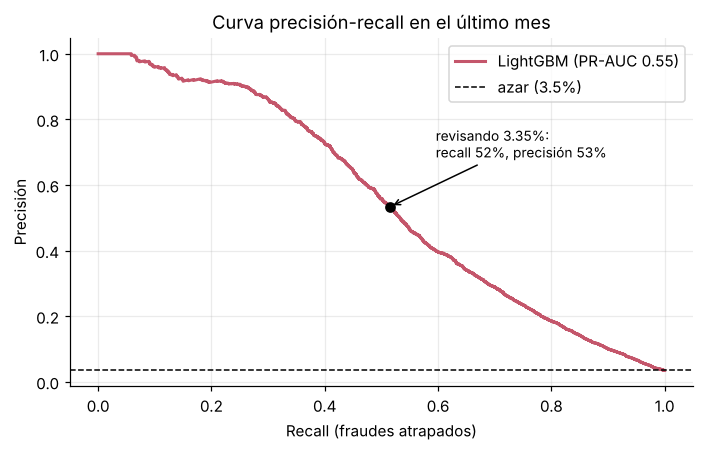

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for nombre, prob, color in [("LightGBM", prob_te, ROJO)]:
    p, r, _ = precision_recall_curve(y_te, prob)
    ax.plot(r, p, color=color, lw=2, label=f"{nombre} (PR-AUC {average_precision_score(y_te, prob):.2f})")
ax.axhline(y_te.mean(), color="k", ls="--", lw=1, label=f"azar ({y_te.mean():.1%})")
k = int(round(PRESUPUESTO * len(y_te))); top = np.argsort(-prob_te)[:k]
r_k, p_k = y_te[top].sum() / y_te.sum(), y_te[top].mean()
ax.scatter([r_k], [p_k], color="k", zorder=3)
ax.annotate(f"revisando {PRESUPUESTO:.2%}:\nrecall {r_k:.0%}, precisión {p_k:.0%}", (r_k, p_k),
            xytext=(r_k + .08, p_k + .15), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("Recall (fraudes atrapados)"); ax.set_ylabel("Precisión")
ax.set_title("Curva precisión-recall en el último mes")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

**Lectura:** con el mismo presupuesto con que los datos sintéticos daban 100%, aquí se atrapa
aproximadamente la mitad de los fraudes, y cerca de la mitad de las alertas son fraude real. Ese es un
resultado creíble para fraude con tarjeta, y es contra lo que se compara cualquier mejora.

## 6. La trampa de la partición aleatoria

Si en vez de separar por tiempo se separa al azar, el mismo cliente queda repartido entre
entrenamiento y prueba. El modelo "reconoce" clientes que ya vio defraudar y la métrica sube sin que
el modelo anticipe mejor el fraude nuevo.

In [11]:
i_ale, i_ale_te = train_test_split(df.index, test_size=len(i_te) / len(df), random_state=42, stratify=df["isFraud"])
i_ale_tr, i_ale_va = train_test_split(i_ale, test_size=len(i_va) / len(i_ale), random_state=1,
                                      stratify=df.loc[i_ale, "isFraud"])
modelo_ale = entrenar(i_ale_tr, i_ale_va)
prob_ale = modelo_ale.predict(df.loc[i_ale_te, ATRIBUTOS], num_iteration=modelo_ale.best_iteration)
comparacion = pd.DataFrame([metricas(y_te, prob_te, "Temporal (honesta)"),
                            metricas(df.loc[i_ale_te, "isFraud"].values, prob_ale, "Aleatoria (optimista)")]).set_index("modelo")
del modelo_ale; gc.collect()
comparacion

,PR-AUC,ROC-AUC,recall revisando 3.35%,precisión revisando 3.35%
modelo,,,,
Temporal (honesta),0.552,0.910,0.516,0.534
Aleatoria (optimista),0.851,0.971,0.779,0.814


In [12]:
# Identificador aproximado de cliente: tarjeta + dirección + día de alta de la tarjeta (día − D1).
# Vesta no publica un ID de cliente; esta aproximación la propuso la comunidad de la competencia.
cliente = (df["card1"].astype(str) + "_" + df["addr1"].astype(str) + "_"
           + np.floor(df["dia"] - df["D1"]).astype(str))

def ya_defraudo(idx_entreno, idx_prueba):
    defraudadores = set(cliente[idx_entreno][df.loc[idx_entreno, "isFraud"] == 1])
    fraudes_prueba = cliente[idx_prueba][df.loc[idx_prueba, "isFraud"] == 1]
    return fraudes_prueba.isin(defraudadores).mean()

print("Fraudes de prueba cuyo cliente ya había defraudado en entrenamiento:")
print(f"  partición aleatoria: {ya_defraudo(i_ale_tr, i_ale_te):.0%}")
print(f"  partición temporal:  {ya_defraudo(i_tr, i_te):.0%}")

Fraudes de prueba cuyo cliente ya había defraudado en entrenamiento:
  partición aleatoria: 84%
  partición temporal:  54%


Con la partición aleatoria, la mayoría de los fraudes de prueba vienen de clientes que el modelo ya
vio defraudar; con la temporal, muchos menos. Por eso el PR-AUC sube tanto. Si alguien reporta ese
número, está midiendo en parte la memoria del modelo, no su capacidad de anticipar fraude nuevo. En el proyecto original la
partición fue aleatoria; con datos sintéticos y sin cambios en el tiempo no importaba, pero con datos
reales sí.

## 7. ¿Qué mira el modelo?

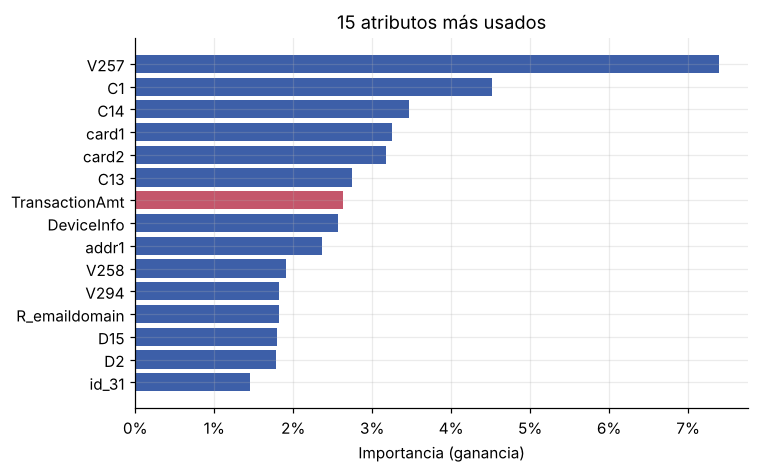

Peso del monto en el modelo: 2.6%   (en los datos sintéticos, el monto y sus derivadas: ~80%)


In [13]:
gain = pd.Series(modelo.feature_importance("gain"), index=ATRIBUTOS)
top15 = (gain / gain.sum()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(top15.index, top15.values, color=[ROJO if c == "TransactionAmt" else AZUL for c in top15.index])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Importancia (ganancia)"); ax.set_title("15 atributos más usados")
plt.tight_layout(); plt.show()
print(f"Peso del monto en el modelo: {gain['TransactionAmt'] / gain.sum():.1%}   (en los datos sintéticos, el monto y sus derivadas: ~80%)")

La importancia está repartida entre muchos atributos: contadores `C`, tarjeta, dirección, dispositivo,
dominio de correo y variables `V` de Vesta. Ninguno domina. Es lo contrario de los datos sintéticos.

### Explicar una alerta

A un analista no le sirve "probabilidad 0.93". Le sirve saber qué empujó esa probabilidad.
LightGBM puede descomponer cada predicción en contribuciones por atributo (valores tipo SHAP).

In [14]:
X_te = df.loc[i_te, ATRIBUTOS]
alerta = int(np.argmax(np.where(y_te == 1, prob_te, -1)))      # el fraude con mayor probabilidad
contrib = modelo.predict(X_te.iloc[[alerta]], num_iteration=modelo.best_iteration, pred_contrib=True)[0]
expl = pd.Series(contrib[:-1], index=ATRIBUTOS)
expl = expl.reindex(expl.abs().sort_values(ascending=False).index).head(8)
valores = X_te.iloc[alerta][expl.index]
print(f"Transacción {df.loc[i_te[alerta], 'TransactionID']}: probabilidad {prob_te[alerta]:.2f}, monto ${df.loc[i_te[alerta], 'TransactionAmt']:.2f}")
explicacion = pd.DataFrame({"valor": valores.astype(str), "empuje hacia fraude (log-odds)": expl.round(2)})
del X_te; gc.collect()
explicacion

Transacción 3540439: probabilidad 1.00, monto $54.22


,valor,empuje hacia fraude (log-odds)
DeviceInfo,SM-G920P Build/NRD90M,2.300
C1,86.0,1.670
V257,4.0,0.710
V45,9.0,0.480
V189,5.0,0.470
V258,4.0,0.440
C12,54.0,0.400
C11,54.0,0.400


## 8. Umbral por costo

Mismos supuestos que en la auditoría, en dólares:
- **Revisar** una transacción: **$3 USD** de tiempo de analista (supuesto).
- **Dejar pasar** un fraude: su monto.

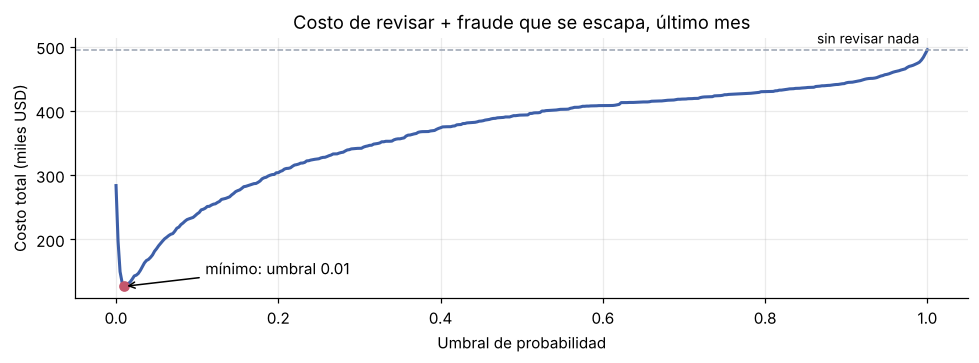

Sin modelo (no revisar):  $495,244 en fraude perdido
Con el modelo:            $127,013  → ahorro de 74%
Umbral 0.01: revisa 28.6% de las transacciones y recupera 91% del monto defraudado
Con capacidad de 3.35%: costo $268,436 → ahorro de 46%, recupera 48% del monto


In [15]:
COSTO_REVISION = 3
monto_te = df.loc[i_te, "TransactionAmt"].values
umbrales = np.linspace(0, 1, 401)
costos = np.array([(prob_te >= u).sum() * COSTO_REVISION + monto_te[(y_te == 1) & (prob_te < u)].sum() for u in umbrales])
mejor = umbrales[costos.argmin()]
no_revisar = monto_te[y_te == 1].sum()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(umbrales, costos / 1e3, color=AZUL, lw=2)
ax.axhline(no_revisar / 1e3, color=GRIS, ls="--", lw=1)
ax.text(.99, no_revisar / 1e3 * 1.02, "sin revisar nada", ha="right", fontsize=9)
ax.scatter([mejor], [costos.min() / 1e3], color=ROJO, zorder=3)
ax.annotate(f"mínimo: umbral {mejor:.2f}", (mejor, costos.min() / 1e3), xytext=(mejor + .1, costos.min() / 1e3 * 1.15),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Umbral de probabilidad"); ax.set_ylabel("Costo total (miles USD)")
ax.set_title("Costo de revisar + fraude que se escapa, último mes")
plt.tight_layout(); plt.show()

revisadas = (prob_te >= mejor).mean()
atrapado = monto_te[(y_te == 1) & (prob_te >= mejor)].sum() / no_revisar
print(f"Sin modelo (no revisar):  ${no_revisar:,.0f} en fraude perdido")
print(f"Con el modelo:            ${costos.min():,.0f}  → ahorro de {1 - costos.min()/no_revisar:.0%}")
print(f"Umbral {mejor:.2f}: revisa {revisadas:.1%} de las transacciones y recupera {atrapado:.0%} del monto defraudado")

# Con la capacidad real del equipo (3.35% de las transacciones)
k = int(round(PRESUPUESTO * len(y_te))); top = np.argsort(-prob_te)[:k]
revisa_k = np.zeros(len(y_te), bool); revisa_k[top] = True
costo_k = k * COSTO_REVISION + monto_te[(y_te == 1) & ~revisa_k].sum()
print(f"Con capacidad de {PRESUPUESTO:.2%}: costo ${costo_k:,.0f} → ahorro de {1 - costo_k/no_revisar:.0%}, recupera {monto_te[(y_te == 1) & revisa_k].sum()/no_revisar:.0%} del monto")

Con $3 por revisión, el óptimo en papel es revisar casi un tercio de las transacciones: el umbral cae
muy bajo porque las probabilidades del modelo rondan la tasa base (3.5%) y revisar es barato frente al
fraude promedio. Ningún equipo revisa un tercio de las operaciones, así que en la práctica manda la
**capacidad**: con el 3.35% de siempre se recupera una parte menor del monto. Si el costo de revisar
sube o la capacidad crece, el umbral se mueve. Ese cruce es una conversación con el negocio, no un
parámetro técnico.

## 9. Sintético contra real

In [16]:
pd.DataFrame({
    "Datos sintéticos (proyecto original)": {
        "Transacciones": "200,000", "Tasa de fraude": "2.5%",
        "ROC-AUC del monto solo": "0.997",
        "¿Una regla simple lo resuelve?": "Sí: monto > $1,500 atrapa 100%",
        "¿El fraude cambia en el tiempo?": "No, tasa plana",
        f"Recall revisando {PRESUPUESTO:.2%}": "100%",
        "Peso del monto en el modelo": "~80%"},
    "IEEE-CIS (real)": {
        "Transacciones": f"{len(df):,}", "Tasa de fraude": f"{df['isFraud'].mean():.1%}",
        "ROC-AUC del monto solo": f"{auc_monto:.3f}",
        "¿Una regla simple lo resuelve?": "No",
        "¿El fraude cambia en el tiempo?": "Sí",
        f"Recall revisando {PRESUPUESTO:.2%}": f"{tabla.loc['LightGBM (partición temporal)', f'recall revisando {PRESUPUESTO:.2%}']:.0%}",
        "Peso del monto en el modelo": f"{gain['TransactionAmt'] / gain.sum():.0%}"},
})

,Datos sintéticos (proyecto original),IEEE-CIS (real)
Transacciones,"200,000","590,540"
Tasa de fraude,2.5%,3.5%
ROC-AUC del monto solo,0.997,0.498
¿Una regla simple lo resuelve?,"Sí: monto > $1,500 atrapa 100%",No
¿El fraude cambia en el tiempo?,"No, tasa plana",Sí
Recall revisando 3.35%,100%,52%
Peso del monto en el modelo,~80%,3%


## 10. Conclusiones y límites

- En datos reales, **atrapar cerca de la mitad del fraude revisando 3% de las transacciones** es un
  resultado útil y creíble. El 100% de los datos sintéticos no lo era.
- La **partición temporal** es obligatoria: la aleatoria infla el resultado porque el modelo
  reconoce tarjetas que ya vio.
- El **umbral** sale de comparar el costo de revisar con el costo del fraude y con la capacidad del
  equipo, no del 0.5.

**Límites:**
- Muchas columnas están anonimizadas; se puede decir *qué* usa el modelo, pero no siempre *qué significa*.
- La hora es aproximada porque Vesta no publicó la fecha de referencia.
- Los costos ($3 por revisión) son supuestos para ilustrar el método.
- No se hizo ingeniería de atributos fuerte (identificadores de cliente, agregados por tarjeta).
  Es el siguiente paso natural, y hay que hacerla calculando solo con datos del pasado para no
  introducir fuga.